<a href="https://colab.research.google.com/github/Raj-vive/TCGA-BRCA-DESeq2/blob/main/BRCA_DESeq2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install pydeseq2 -q
import pandas as pd, numpy as np
import matplotlib.pyplot as plt


!pip install pydeseq2 -q
import requests, json, io, tarfile
import pandas as pd, numpy as np

def get_files(sample_type, n):
    filters = {"op":"and","content":[
        {"op":"in","content":{"field":"cases.project.project_id","value":["TCGA-BRCA"]}},
        {"op":"in","content":{"field":"data_type","value":["Gene Expression Quantification"]}},
        {"op":"in","content":{"field":"analysis.workflow_type","value":["STAR - Counts"]}},
        {"op":"in","content":{"field":"cases.samples.sample_type","value":[sample_type]}}]}
    params = {"filters": json.dumps(filters), "size": n,
              "fields": "file_id,file_name,cases.submitter_id"}
    r = requests.get("https://api.gdc.cancer.gov/files", params=params)
    return r.json()["data"]["hits"]

tumor = get_files("Primary Tumor", 20)
normal = get_files("Solid Tissue Normal", 20)
print(len(tumor), len(normal))

def get_counts(hit):
    url = f"https://api.gdc.cancer.gov/data/{hit['file_id']}"
    df = pd.read_csv(io.StringIO(requests.get(url).text),
                     sep="\t", comment="#", index_col="gene_id")
    df = df[~df.index.str.startswith("N_")]   # remove summary rows
    return df["unstranded"]

series, labels = {}, {}
for cond, hits in [("tumor", tumor), ("normal", normal)]:
    for h in hits:
        name = f"{cond}_{h['file_id'][:8]}"
        series[name] = get_counts(h)
        labels[name] = cond

counts = pd.DataFrame(series).T.astype(int)   # samples x genes
meta = pd.DataFrame({"condition": pd.Series(labels)})
print(counts.shape, meta.condition.value_counts())



20 20
(40, 60660) condition
tumor     20
normal    20
Name: count, dtype: int64


In [16]:
counts = counts.loc[:, counts.sum(axis=0) >= 10]
print(counts.shape)

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

dds = DeseqDataSet(counts=counts, metadata=meta, design="~condition")
dds.deseq2()
stats = DeseqStats(dds, contrast=["condition", "tumor", "normal"])
stats.summary()
res = stats.results_df


(40, 44127)
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.09 seconds.

Fitting dispersions...
... done in 75.05 seconds.

Fitting dispersion trend curve...
... done in 2.32 seconds.

Fitting MAP dispersions...
... done in 86.84 seconds.

Fitting LFCs...
... done in 60.80 seconds.

Calculating cook's distance...
... done in 0.18 seconds.

Replacing 9310 outlier genes.

Fitting dispersions...
... done in 14.07 seconds.

Fitting MAP dispersions...
... done in 15.72 seconds.

Fitting LFCs...
... done in 11.57 seconds.

Running Wald tests...
... done in 12.80 seconds.



Log2 fold change & Wald test p-value: condition tumor vs normal
                       baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                               
ENSG00000000003.15  3521.834550       -0.673063  0.264823 -2.541556   
ENSG00000000005.6    610.631782       -5.409618  0.587045 -9.214995   
ENSG00000000419.13  1895.839215        0.230485  0.132354  1.741423   
ENSG00000000457.14  1477.121426        0.434987  0.151127  2.878294   
ENSG00000000460.17   488.086165        1.295298  0.156356  8.284275   
...                         ...             ...       ...       ...   
ENSG00000288667.1      0.243029        0.631036  2.303731  0.273919   
ENSG00000288669.1      0.274085       -0.998015  1.392466 -0.716725   
ENSG00000288670.1    404.667132        0.074574  0.195408  0.381635   
ENSG00000288674.1     10.111634       -0.580516  0.276715 -2.097881   
ENSG00000288675.1     17.337312        1.273302  0.257611  4.942727   

            

In [17]:
res = stats.results_df
sig = res[(res.padj < 0.05) & (res.log2FoldChange.abs() > 1)]
print(len(sig), "significant genes")
print((sig.log2FoldChange > 0).sum(), "up in tumor,", (sig.log2FoldChange < 0).sum(), "down in tumor")
sig.sort_values("padj").head(10)


8799 significant genes
4767 up in tumor, 4032 down in tumor


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_id,,,,,,
ENSG00000123500.10,2164.389467,7.110014,0.422433,16.831101,1.443916e-63,5.247769e-59
ENSG00000099953.10,9442.432810,6.245905,0.408060,15.306345,6.935278e-53,1.260279e-48
ENSG00000230838.1,105.477503,5.400477,0.425927,12.679344,7.697290e-37,9.325010e-33
ENSG00000183682.8,460.784256,3.117618,0.262144,11.892787,1.290287e-32,1.172355e-28
ENSG00000090889.12,811.578719,4.312352,0.363796,11.853772,2.057176e-32,1.495320e-28
ENSG00000130226.17,107.335941,-4.800794,0.405772,-11.831273,2.690289e-32,1.629598e-28
ENSG00000117650.13,808.030093,4.764122,0.403935,11.794270,4.178057e-32,2.169247e-28
ENSG00000127564.17,678.166845,4.996492,0.425810,11.734093,8.523540e-32,3.872244e-28
ENSG00000183856.11,1185.760402,4.120336,0.354998,11.606643,3.812949e-31,1.539753e-27


                    gene_name  log2FoldChange          padj
gene_id                                                    
ENSG00000123500.10    COL10A1        7.110014  5.247769e-59
ENSG00000099953.10      MMP11        6.245905  1.260279e-48
ENSG00000230838.1   LINC01614        5.400477  9.325010e-33
ENSG00000183682.8       BMP8A        3.117618  1.172355e-28
ENSG00000090889.12      KIF4A        4.312352  1.495320e-28
ENSG00000130226.17       DPP6       -4.800794  1.629598e-28
ENSG00000117650.13       NEK2        4.764122  2.169247e-28
ENSG00000127564.17     PKMYT1        4.996492  3.872244e-28
ENSG00000183856.11     IQGAP3        4.120336  1.539753e-27
ENSG00000187730.9       GABRD        3.604918  1.633721e-27


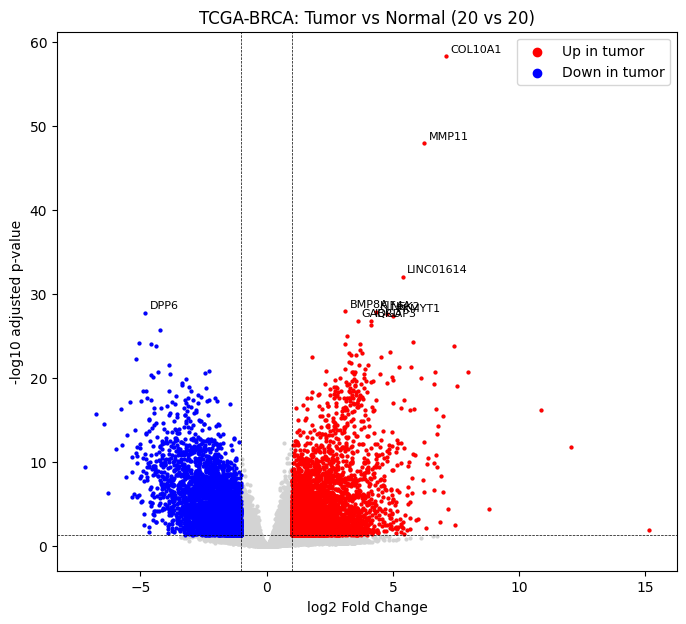

In [18]:
import matplotlib.pyplot as plt

# gene names (skip if you already ran this)
r = requests.get("https://api.gdc.cancer.gov/data/" + tumor[0]["file_id"])
ann = pd.read_csv(io.StringIO(r.text), sep="\t", comment="#", index_col="gene_id")
res["gene_name"] = res.index.map(ann["gene_name"])

sig = res[(res.padj < 0.05) & (res.log2FoldChange.abs() > 1)]
top = sig.sort_values("padj").head(10)
print(top[["gene_name", "log2FoldChange", "padj"]])

plt.figure(figsize=(8, 7))
plt.scatter(res.log2FoldChange, -np.log10(res.padj), s=4, c="lightgrey")
up = sig[sig.log2FoldChange > 0]
down = sig[sig.log2FoldChange < 0]
plt.scatter(up.log2FoldChange, -np.log10(up.padj), s=4, c="red", label="Up in tumor")
plt.scatter(down.log2FoldChange, -np.log10(down.padj), s=4, c="blue", label="Down in tumor")
for _, row in top.iterrows():
    plt.annotate(row.gene_name, (row.log2FoldChange, -np.log10(row.padj)),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.axvline(1, ls="--", c="k", lw=0.5); plt.axvline(-1, ls="--", c="k", lw=0.5)
plt.axhline(-np.log10(0.05), ls="--", c="k", lw=0.5)
plt.xlabel("log2 Fold Change"); plt.ylabel("-log10 adjusted p-value")
plt.title("TCGA-BRCA: Tumor vs Normal (20 vs 20)")
plt.legend(markerscale=3)
plt.savefig("volcano_labeled.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:
!pip install gseapy -q
import gseapy as gp

strict = res[(res.padj < 0.01) & (res.log2FoldChange.abs() > 2)].dropna(subset=["gene_name"])
up_genes = strict[strict.log2FoldChange > 0].sort_values("padj").gene_name.drop_duplicates().head(300).tolist()
down_genes = strict[strict.log2FoldChange < 0].sort_values("padj").gene_name.drop_duplicates().head(300).tolist()
print(len(up_genes), len(down_genes))

for name, genes in [("up", up_genes), ("down", down_genes)]:
    enr = gp.enrichr(gene_list=genes,
                     gene_sets=["KEGG_2021_Human", "GO_Biological_Process_2023"],
                     organism="human", outdir=None)
    out = enr.results.sort_values("Adjusted P-value").head(10)
    print(f"\nTop pathways, {name} in tumor")
    print(out[["Gene_set", "Term", "Adjusted P-value"]].to_string(index=False))
    out.to_csv(f"enrichment_{name}.csv", index=False)


300 300

Top pathways, up in tumor
                  Gene_set                                                                      Term  Adjusted P-value
GO_Biological_Process_2023                         Mitotic Sister Chromatid Segregation (GO:0000070)      1.543381e-19
GO_Biological_Process_2023                                 Mitotic Spindle Organization (GO:0007052)      5.821625e-16
GO_Biological_Process_2023                        Spindle Assembly Checkpoint Signaling (GO:0071173)      2.471873e-15
GO_Biological_Process_2023    Microtubule Cytoskeleton Organization Involved In Mitosis (GO:1902850)      2.471873e-15
GO_Biological_Process_2023                         Mitotic Spindle Checkpoint Signaling (GO:0071174)      2.471873e-15
GO_Biological_Process_2023                Mitotic Spindle Assembly Checkpoint Signaling (GO:0007094)      2.471873e-15
GO_Biological_Process_2023 Negative Regulation Of Mitotic Metaphase/Anaphase Transition (GO:0045841)      7.425847e-15
           KE

In [23]:
res.to_csv("deseq2_results.csv")
import os
print([f for f in os.listdir() if f.endswith((".csv", ".png"))])


['enrichment_up.csv', 'volcano_labeled.png', 'deseq2_results.csv', 'enrichment_down.csv']


In [24]:
!zip brca_results.zip volcano_labeled.png deseq2_results.csv enrichment_up.csv enrichment_down.csv
from google.colab import files
files.download("brca_results.zip")


  adding: volcano_labeled.png (deflated 12%)
  adding: deseq2_results.csv (deflated 54%)
  adding: enrichment_up.csv (deflated 59%)
  adding: enrichment_down.csv (deflated 52%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>